# 27 — Week 7 (extension): uncertainty-aware MPC with conformal bounds (RQ3 → RQ4)

**Question.** Notebook 26 showed that the point forecast of LightGBM + covariates gives no benefit over a flat
persistence trajectory inside the MPC. Does the **uncertainty** information of notebook 24 help instead?

**Design (provisional; `ScenarioMPC` in `src/control/scenario_mpc.py`).**
- At every minute the controller gets **three trajectories**: lower bound, point forecast and upper bound of the 90%
  conformal interval at h = 1, 5, 15 (linear interpolation in between). One shared first move must suit all three
  (non-anticipativity: P(t) is measured); later moves may differ per scenario; objective = mean over the scenarios of
  the notebook-26 objective. Battery, ramp limit, weights and horizon are unchanged (R = 1 kW/min, P_max = 2E).
- Two forecasters, each with its **own** conformal interval: `lightgbm_cov` and `persistence`. The persistence band is
  the key control: it shows whether a gain comes from the model or only from knowing the typical size of changes.
- Conformal method per forecaster ∈ {ACI, Mondrian by predicted change}, configurations as chosen in notebook 24.
  **Selection on validation** (rule fixed beforehand): the method with the smaller excess ramp at E = 2 kWh
  (ties → ACI).
- Test: intervals are rebuilt exactly as in notebook 24 (continuous run from the start of validation; cell 5 checks
  them against the stored test intervals), a freeze record is written, and the test month is simulated once:
  E = 1, 2, 5 kWh at R = 1 and E = 5 kWh at R = 0.5. References = notebook-26 results (oracle, point model,
  persistence, myopic) on the same minutes.

**Run time:** about 5 ms per step (three scenarios) → about 3.5 min per run; validation ≈ 30 min, test ≈ 30 min.
Runs are cached in `experiments/week7_mpc_band/`. Keep the lid open (`caffeinate -dis`). Save with Cmd+S after cell 9,
then run cell 10 (export).


In [1]:
# Cell 1: setup
import sys, json, time, hashlib, subprocess, warnings
from pathlib import Path
import numpy as np
import polars as pl
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
from evaluation import conformal as CF
from control import battery_mpc as B
from control import scenario_mpc as SM

R_MAIN, E_VAL, E_SEL = 1.0, [1.0, 2.0], 2.0
TEST_RUNS = [(1.0, 1.0), (2.0, 1.0), (5.0, 1.0), (5.0, 0.5)]          # (E, R)
FORECASTERS = ["lightgbm_cov", "persistence"]
METHODS = ["aci", "mondrian_pc"]
REP, FIG = ROOT / "reports" / "week7", ROOT / "reports" / "figures" / "week7"
CACHE = ROOT / "experiments" / "week7_mpc_band"
CACHE.mkdir(parents=True, exist_ok=True)
FREEZE_F = REP / "mpc_band_test_freeze.json"
COL = {"no battery": "#52514e", "oracle": "#2a78d6", "model": "#eb6834", "persistence": "#1baf7a", "myopic": "#eda100",
       "band lightgbm_cov": "#e87ba4", "band persistence": "#6250d6"}
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6})

md_ = pl.read_parquet(ROOT / "data" / "processed" / "model_dataset.parquet")
P = md_["P_kW"].fill_null(np.nan).to_numpy().astype(float)
VALID = md_["valid"].to_numpy() & np.isfinite(P)
SPLIT = np.array(md_["split"].to_list(), dtype=object)
EP = md_["minute_epoch"].to_numpy()
V60 = CF.vol60_series(md_)
SEGS = {s: B.segments(VALID & (SPLIT == s), min_len=60) for s in ("val", "test")}
CHOSEN = json.loads((REP / "conformal_val.json").read_text())["chosen"]
REF_VAL = pl.read_csv(REP / "mpc_val.csv")
REF_TEST = pl.read_csv(REP / "mpc_test.csv")
print({k: v for k, v in CHOSEN.items() if k.split("|")[0] in FORECASTERS and k.split("|")[2] in METHODS})
print("notebook-26 references loaded:", REF_VAL.height, "validation rows,", REF_TEST.height, "test rows")
print("freeze record exists:", FREEZE_F.exists())

def parse(name):
    p = name.split("|"); c = {"method": p[0], "scale": p[1]}
    for x in p[2:]:
        if x.startswith("W"): c["W"] = int(x[1:])
        if x.startswith("g"): c["gamma"] = float(x[1:])
    return c

def band_dict(per):
    """per[h] = {minute: (lo, yhat, hi)} -> {minute: (lo[3], mid[3], hi[3])} where all horizons exist."""
    keys = set(per[1]) & set(per[5]) & set(per[15])
    return {t: tuple([per[h][t][j] for h in (1, 5, 15)] for j in range(3)) for t in keys}

def run_band(split, fc, meth, E, R, bands):
    f = CACHE / f"{split}_{fc}_{meth}_E{E:g}_R{R:g}.parquet"
    if f.exists():
        d = pl.read_parquet(f)
        return {k: d[k].to_numpy() for k in d.columns} | {"fallback": int(d["fallback"][0])}
    m = SM.ScenarioMPC(E, 2.0 * E, R, S=3)
    t0 = time.time()
    r = SM.simulate_band(P, SEGS[split], m, bands)
    pl.DataFrame({k: r[k] for k in ("minute", "P", "g", "soc", "pc", "pd", "ok", "first")}).with_columns(
        pl.lit(r["fallback"]).alias("fallback")).write_parquet(f)
    print(f"  {split} {fc:12s} {meth:11s} E={E:g} R={R:g}: {time.time() - t0:5.0f} s", flush=True)
    return r


{'lightgbm_cov|1|aci': 'aci|abs|W10080|g0.01', 'lightgbm_cov|1|mondrian_pc': 'mondrian_pc|res60|W1440', 'lightgbm_cov|5|aci': 'aci|abs|W10080|g0.005', 'lightgbm_cov|5|mondrian_pc': 'mondrian_pc|res60|W1440', 'lightgbm_cov|15|aci': 'aci|vol60|W10080|g0.001', 'lightgbm_cov|15|mondrian_pc': 'mondrian_pc|abs|W1440', 'persistence|1|aci': 'aci|abs|W1440|g0.01', 'persistence|1|mondrian_pc': 'mondrian_pc|res60|W10080', 'persistence|5|aci': 'aci|vol60|W10080|g0.001', 'persistence|5|mondrian_pc': 'mondrian_pc|vol60|W10080', 'persistence|15|aci': 'aci|vol60|W4320|g0.001', 'persistence|15|mondrian_pc': 'mondrian_pc|vol60|W4320'}
notebook-26 references loaded: 21 validation rows, 31 test rows
freeze record exists: False


In [2]:
# Cell 2: unit checks of the scenario MPC (synthetic)
checks = []
n = 500
Ps = np.full(n, 30.0); Ps[250:] += 6.0
seg = B.segments(np.ones(n, bool))
r1 = B.simulate(Ps, seg, "persistence", B.MPC(2.0, 4.0, 1.0))
flat = {t: ([Ps[t]] * 3, [Ps[t]] * 3, [Ps[t]] * 3) for t in range(n)}
r3 = SM.simulate_band(Ps, seg, SM.ScenarioMPC(2.0, 4.0, 1.0, S=3), flat)
checks.append(("three identical flat scenarios = notebook-26 persistence MPC", np.allclose(r1["g"], r3["g"], atol=1e-4), None))
m = SM.ScenarioMPC(2.0, 4.0, 1.0, S=3)
pc, pd, ok = m.step(SM.trajectory_band(30.0, [29, 27, 25], [30, 30, 30], [31, 33, 35]), 0.5, 30.0)
first = [(float(m.pc[s].value[0]), float(m.pd[s].value[0])) for s in range(3)]
checks.append(("non-anticipativity: one first move for all scenarios", ok and np.allclose(first, first[0], atol=1e-6), first[0]))
up = {t: ([Ps[t]] * 3, [Ps[t]] * 3, [Ps[t] + 8, Ps[t] + 8, Ps[t] + 8]) for t in range(n)}
ru = SM.simulate_band(Ps, seg, SM.ScenarioMPC(2.0, 4.0, 1.0, S=3), up)
act = float(np.abs(ru["g"][100:250] - Ps[100:250]).mean())
checks.append(("an upper scenario with a jump larger than P_max (8 kW > 4 kW) makes the controller act before any load change (mean |g - P| > 0.1 kW)",
               act > 0.1 and float(np.abs(r1["g"][100:250] - Ps[100:250]).mean()) < 1e-3, round(act, 3)))
for name, ok_, val in checks:
    print(f"{'PASS' if ok_ else 'FAIL'}  {name}" + (f"  [{val}]" if val is not None else ""))
UNIT_OK = all(ok_ for _, ok_, _ in checks)
print("\nALL UNIT CHECKS PASSED" if UNIT_OK else "\nUNIT CHECKS FAILED: stop and send this output")


PASS  three identical flat scenarios = notebook-26 persistence MPC
PASS  non-anticipativity: one first move for all scenarios  [(3.5111897955016386e-10, 3.684034850867631e-10)]
PASS  an upper scenario with a jump larger than P_max (8 kW > 4 kW) makes the controller act before any load change (mean |g - P| > 0.1 kW)  [0.39]

ALL UNIT CHECKS PASSED


In [3]:
# Cell 3: validation: conformal bands (as in notebook 24's validation protocol) and band-MPC runs (~30 min, cached)
assert UNIT_OK
VAL = CF.load_val(ROOT, FORECASTERS, seed=0)
BANDS_VAL = {}
for fc in FORECASTERS:
    for meth in METHODS:
        per = {}
        for h in (1, 5, 15):
            f = CF.frame(VAL, md_, fc, h, V60)
            n = len(f["y"])
            _, r, iv = CF.run_config(f, h, parse(CHOSEN[f"{fc}|{h}|{meth}"]), np.arange(n) < n // 2)
            per[h] = {int(t): (lo, yh, hi) for t, lo, yh, hi, hv in zip(f["minute"], iv["lo"], f["yhat"], iv["hi"], iv["have"]) if hv}
        BANDS_VAL[(fc, meth)] = band_dict(per)
        print(f"  bands {fc} {meth}: {len(BANDS_VAL[(fc, meth)]):,} minutes")
rows = []
for fc in FORECASTERS:
    for meth in METHODS:
        for E in E_VAL:
            r = run_band("val", fc, meth, E, R_MAIN, BANDS_VAL[(fc, meth)])
            rows.append({"split": "val", "forecaster": fc, "method": meth, "E_kWh": E, "R": R_MAIN, **B.ramp_metrics(r, R_MAIN),
                         "fallback": int(r["fallback"])})
BVAL = pl.DataFrame(rows)
BVAL.write_csv(REP / "mpc_band_val.csv")


  bands lightgbm_cov aci: 42,483 minutes
  bands lightgbm_cov mondrian_pc: 42,231 minutes
  bands persistence aci: 42,483 minutes
  bands persistence mondrian_pc: 42,483 minutes
  val lightgbm_cov aci         E=1 R=1:    87 s
  val lightgbm_cov aci         E=2 R=1:    86 s
  val lightgbm_cov mondrian_pc E=1 R=1:    83 s
  val lightgbm_cov mondrian_pc E=2 R=1:    84 s
  val persistence  aci         E=1 R=1:    91 s
  val persistence  aci         E=2 R=1:    95 s
  val persistence  mondrian_pc E=1 R=1:    88 s
  val persistence  mondrian_pc E=2 R=1:    86 s


In [4]:
# Cell 4: validation table and selection of the conformal method per forecaster (rule in the header)
SHOWB = ["forecaster", "method", "E_kWh", "viol_steps", "viol_share", "viol_excess_kW", "max_ramp", "throughput_kWh", "soc_min", "soc_max", "solver_fail", "fallback"]
pl.Config.set_tbl_rows(40); pl.Config.set_tbl_width_chars(220)
print(BVAL.select(SHOWB).with_columns(pl.col(pl.Float64).round(4)))
print("\nnotebook-26 references on validation (R = 1):")
print(REF_VAL.filter(pl.col("E_kWh").is_in(E_VAL)).select("E_kWh", "scenario", "viol_steps", pl.col("viol_excess_kW").round(2)).sort("E_kWh", "scenario"))
SEL = {}
for fc in FORECASTERS:
    g = BVAL.filter((pl.col("forecaster") == fc) & (pl.col("E_kWh") == E_SEL))
    ex = {m: g.filter(pl.col("method") == m)["viol_excess_kW"][0] for m in METHODS}
    SEL[fc] = "aci" if ex["aci"] <= ex["mondrian_pc"] else "mondrian_pc"
    print(f"selected for {fc}: {SEL[fc]}  (excess at E = {E_SEL:g}: {ex})")


shape: (8, 12)
┌──────────────┬─────────────┬───────┬────────────┬───┬─────────┬─────────┬─────────────┬──────────┐
│ forecaster   ┆ method      ┆ E_kWh ┆ viol_steps ┆ … ┆ soc_min ┆ soc_max ┆ solver_fail ┆ fallback │
│ ---          ┆ ---         ┆ ---   ┆ ---        ┆   ┆ ---     ┆ ---     ┆ ---         ┆ ---      │
│ str          ┆ str         ┆ f64   ┆ i64        ┆   ┆ f64     ┆ f64     ┆ i64         ┆ i64      │
╞══════════════╪═════════════╪═══════╪════════════╪═══╪═════════╪═════════╪═════════════╪══════════╡
│ lightgbm_cov ┆ aci         ┆ 1.0   ┆ 190        ┆ … ┆ 0.3806  ┆ 0.6965  ┆ 0           ┆ 153      │
│ lightgbm_cov ┆ aci         ┆ 2.0   ┆ 66         ┆ … ┆ 0.3553  ┆ 0.739   ┆ 0           ┆ 153      │
│ lightgbm_cov ┆ mondrian_pc ┆ 1.0   ┆ 196        ┆ … ┆ 0.3806  ┆ 0.7262  ┆ 0           ┆ 405      │
│ lightgbm_cov ┆ mondrian_pc ┆ 2.0   ┆ 62         ┆ … ┆ 0.3553  ┆ 0.6941  ┆ 0           ┆ 405      │
│ persistence  ┆ aci         ┆ 1.0   ┆ 197        ┆ … ┆ 0.3669  ┆ 0.7036  ┆ 

In [5]:
# Cell 5: test bands rebuilt exactly as in notebook 24 (continuous validation -> test run); check vs stored intervals
TEST = CF.load_test(ROOT, FORECASTERS, seed=0)
STORED = pl.read_parquet(REP / "conformal_test_intervals.parquet")
BANDS_TEST, rep = {}, []
for fc in FORECASTERS:
    meth = SEL[fc]
    per = {}
    for h in (1, 5, 15):
        fv, ft = CF.frame(VAL, md_, fc, h, V60), CF.frame(TEST, md_, fc, h, V60)
        f, is_test = CF.concat_frames(fv, ft)
        _, r, iv = CF.run_config(f, h, parse(CHOSEN[f"{fc}|{h}|{meth}"]), ~is_test)
        k = is_test & iv["have"]
        per[h] = {int(t): (lo, yh, hi) for t, lo, yh, hi in zip(f["minute"][k], iv["lo"][k], f["yhat"][k], iv["hi"][k])}
        st = STORED.filter((pl.col("model") == fc) & (pl.col("h") == h) & (pl.col("method") == meth)).sort("minute_epoch")
        same = len(st) == int(k.sum()) and np.allclose(st["lo"].to_numpy(), iv["lo"][k]) and np.allclose(st["hi"].to_numpy(), iv["hi"][k])
        rep.append({"forecaster": fc, "method": meth, "h": h, "n": int(k.sum()), "matches_notebook_24": bool(same)})
    BANDS_TEST[fc] = band_dict(per)
REP_TAB = pl.DataFrame(rep)
print(REP_TAB)
REPRO_OK = bool(REP_TAB["matches_notebook_24"].all())
print("REPRODUCTION PASSED: test bands equal the stored notebook-24 intervals" if REPRO_OK else "REPRODUCTION FAILED: stop and send this output")


shape: (6, 5)
┌──────────────┬─────────────┬─────┬───────┬─────────────────────┐
│ forecaster   ┆ method      ┆ h   ┆ n     ┆ matches_notebook_24 │
│ ---          ┆ ---         ┆ --- ┆ ---   ┆ ---                 │
│ str          ┆ str         ┆ i64 ┆ i64   ┆ bool                │
╞══════════════╪═════════════╪═════╪═══════╪═════════════════════╡
│ lightgbm_cov ┆ mondrian_pc ┆ 1   ┆ 42575 ┆ true                │
│ lightgbm_cov ┆ mondrian_pc ┆ 5   ┆ 42567 ┆ true                │
│ lightgbm_cov ┆ mondrian_pc ┆ 15  ┆ 42547 ┆ true                │
│ persistence  ┆ aci         ┆ 1   ┆ 42575 ┆ true                │
│ persistence  ┆ aci         ┆ 5   ┆ 42567 ┆ true                │
│ persistence  ┆ aci         ┆ 15  ┆ 42547 ┆ true                │
└──────────────┴─────────────┴─────┴───────┴─────────────────────┘
REPRODUCTION PASSED: test bands equal the stored notebook-24 intervals


In [6]:
# Cell 6: freeze record (BEFORE the test month is simulated)
assert UNIT_OK and REPRO_OK
def sha(p):
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()
try:
    git = subprocess.run(["git", "rev-parse", "HEAD"], cwd=ROOT, capture_output=True, text=True).stdout.strip() or None
except Exception:  # noqa: BLE001
    git = None
files = ["reports/week4/test_predictions.parquet", "reports/week7/conformal_test_intervals.parquet",
         "reports/week7/conformal_val.json", "src/control/battery_mpc.py", "src/control/scenario_mpc.py", "src/evaluation/conformal.py"]
freeze = {"frozen_at": time.strftime("%Y-%m-%d %H:%M:%S"), "git_head": git, "selected_method": SEL,
          "test_runs": TEST_RUNS, "rule": f"method with the smaller validation excess ramp at E = {E_SEL:g} kWh, R = {R_MAIN}",
          "inputs_sha256": {f: sha(ROOT / f) for f in files}}
if FREEZE_F.exists():
    print("NOTE: a freeze record already exists (the test month was simulated before); writing a second record")
    FREEZE_F = REP / f"mpc_band_test_freeze_{time.strftime('%Y%m%d_%H%M%S')}.json"
FREEZE_F.write_text(json.dumps(freeze, indent=1))
print(f"freeze record {FREEZE_F.name} | selected {SEL}")


freeze record mpc_band_test_freeze.json | selected {'lightgbm_cov': 'mondrian_pc', 'persistence': 'aci'}


In [7]:
# Cell 7: TEST month (once): band MPC for both forecasters (~30 min, cached)
assert FREEZE_F.exists()
rows = []
for fc in FORECASTERS:
    for E, R in TEST_RUNS:
        r = run_band("test", fc, SEL[fc], E, R, BANDS_TEST[fc])
        rows.append({"split": "test", "forecaster": fc, "method": SEL[fc], "E_kWh": E, "R": R, **B.ramp_metrics(r, R),
                     "fallback": int(r["fallback"])})
BTEST = pl.DataFrame(rows)
BTEST.write_csv(REP / "mpc_band_test.csv")
fr = json.loads(FREEZE_F.read_text())
fr["test_run_at"] = time.strftime("%Y-%m-%d %H:%M:%S"); fr["test_table_sha256"] = sha(REP / "mpc_band_test.csv")
FREEZE_F.write_text(json.dumps(fr, indent=1))
print("test runs done")


  test lightgbm_cov mondrian_pc E=1 R=1:    82 s
  test lightgbm_cov mondrian_pc E=2 R=1:    83 s
  test lightgbm_cov mondrian_pc E=5 R=1:    92 s
  test lightgbm_cov mondrian_pc E=5 R=0.5:   103 s
  test persistence  aci         E=1 R=1:    97 s
  test persistence  aci         E=2 R=1:   102 s
  test persistence  aci         E=5 R=1:   106 s
  test persistence  aci         E=5 R=0.5:   107 s
test runs done


shape: (24, 8)
┌─────┬───────┬───────────────────┬────────────┬────────────┬────────────────┬──────────┬────────────────┐
│ R   ┆ E_kWh ┆ controller        ┆ viol_steps ┆ viol_share ┆ viol_excess_kW ┆ max_ramp ┆ throughput_kWh │
│ --- ┆ ---   ┆ ---               ┆ ---        ┆ ---        ┆ ---            ┆ ---      ┆ ---            │
│ f64 ┆ f64   ┆ str               ┆ i64        ┆ f64        ┆ f64            ┆ f64      ┆ f64            │
╞═════╪═══════╪═══════════════════╪════════════╪════════════╪════════════════╪══════════╪════════════════╡
│ 0.5 ┆ 5.0   ┆ band persistence  ┆ 0          ┆ 0.0        ┆ 0.0            ┆ 0.5      ┆ 44.012         │
│ 0.5 ┆ 5.0   ┆ band lightgbm_cov ┆ 0          ┆ 0.0        ┆ 0.0            ┆ 0.5      ┆ 44.437         │
│ 0.5 ┆ 5.0   ┆ oracle            ┆ 0          ┆ 0.0        ┆ 0.0            ┆ 0.5      ┆ 29.025         │
│ 0.5 ┆ 5.0   ┆ model             ┆ 0          ┆ 0.0        ┆ 0.0            ┆ 0.5      ┆ 43.096         │
│ 0.5 ┆ 5.0   ┆ persis

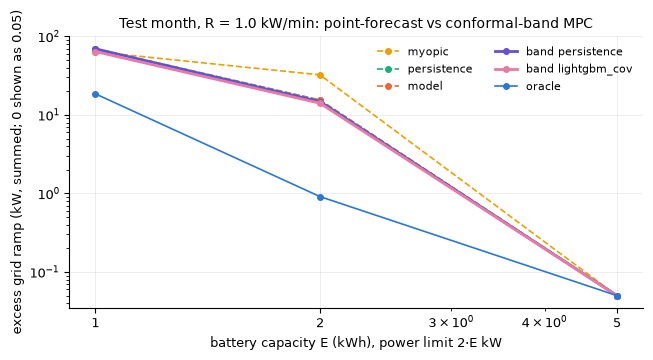

In [8]:
# Cell 8: test comparison with the notebook-26 controllers on the same minutes; figures
ref = (REF_TEST.filter(pl.col("scenario") != "no battery").select("R", "E_kWh", pl.col("scenario").alias("controller"),
       "viol_steps", "viol_share", "viol_excess_kW", "max_ramp", "throughput_kWh"))
band = BTEST.select("R", "E_kWh", ("band " + pl.col("forecaster")).alias("controller"), "viol_steps", "viol_share",
                    "viol_excess_kW", "max_ramp", "throughput_kWh")
CMP = pl.concat([ref, band]).join(pl.DataFrame({"R": [r for _, r in TEST_RUNS], "E_kWh": [e for e, _ in TEST_RUNS]}), on=["R", "E_kWh"])
CMP = CMP.sort("R", "E_kWh", "viol_excess_kW")
CMP.write_csv(REP / "mpc_band_vs_point_test.csv")
print(CMP.with_columns(pl.col(pl.Float64).round(3)))
nb = REF_TEST.filter(pl.col("scenario") == "no battery").select("R", "viol_steps", pl.col("viol_excess_kW").round(1))
print("\nno battery:", nb.to_dicts())

def val_of(E, R, c):
    return CMP.filter((pl.col("E_kWh") == E) & (pl.col("R") == R) & (pl.col("controller") == c))["viol_excess_kW"][0]
gain = []
for E, R in TEST_RUNS:
    orc, my = val_of(E, R, "oracle"), val_of(E, R, "myopic")
    row = {"E_kWh": E, "R": R, "excess_oracle": orc, "excess_myopic": my}
    for c in ("model", "persistence", "band lightgbm_cov", "band persistence"):
        v = val_of(E, R, c)
        row[f"excess_{c}"] = v
        row[f"share_of_oracle_gain_{c}"] = (my - v) / (my - orc) if my - orc > 1e-9 else float("nan")
    gain.append(row)
GAIN = pl.DataFrame(gain)
GAIN.write_csv(REP / "mpc_band_gain_test.csv")
print("\nshare of the oracle's improvement over the myopic controller (1 = as good as perfect foresight):")
print(GAIN.select("E_kWh", "R", *[c for c in GAIN.columns if c.startswith("share")]).with_columns(pl.col(pl.Float64).round(3)))

fig, ax = plt.subplots(figsize=(6.6, 3.6))
for c in ("myopic", "persistence", "model", "band persistence", "band lightgbm_cov", "oracle"):
    s = CMP.filter((pl.col("controller") == c) & (pl.col("R") == R_MAIN)).sort("E_kWh")
    ax.plot(s["E_kWh"], np.maximum(s["viol_excess_kW"].to_numpy(), 0.05), marker="o", ms=4, lw=2 if c.startswith("band") else 1.2,
            ls="-" if c.startswith("band") or c == "oracle" else "--", color=COL[c], label=c)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xticks([1, 2, 5], ["1", "2", "5"])
ax.set_xlabel("battery capacity E (kWh), power limit 2·E kW"); ax.set_ylabel("excess grid ramp (kW, summed; 0 shown as 0.05)")
ax.set_title(f"Test month, R = {R_MAIN} kW/min: point-forecast vs conformal-band MPC", fontsize=10)
ax.legend(frameon=False, fontsize=8, ncol=2)
fig.tight_layout(); fig.savefig(FIG / "10_mpc_band_vs_point_test.png", dpi=160, bbox_inches="tight"); plt.show()


In [9]:
# Cell 9: summary
summ = {"freeze_record": FREEZE_F.name, "selected_method": SEL, "val": BVAL.to_dicts(), "test": BTEST.to_dicts(),
        "comparison_test": CMP.to_dicts(), "gain_test": GAIN.to_dicts()}
(REP / "mpc_band_summary.json").write_text(json.dumps(summ, indent=1, default=str))
for E, R in TEST_RUNS:
    s = CMP.filter((pl.col("E_kWh") == E) & (pl.col("R") == R)).sort("viol_excess_kW")
    print(f"E = {E:g} kWh, R = {R:g}: " + " < ".join(f"{c} ({v:.1f})" for c, v in zip(s["controller"], s["viol_excess_kW"])))


E = 1 kWh, R = 1: oracle (18.6) < myopic (63.6) < band lightgbm_cov (64.1) < model (69.0) < band persistence (69.5) < persistence (69.7)
E = 2 kWh, R = 1: oracle (0.9) < band lightgbm_cov (14.1) < band persistence (14.8) < model (15.3) < persistence (15.5) < myopic (32.3)
E = 5 kWh, R = 1: band lightgbm_cov (0.0) < myopic (0.0) < persistence (0.0) < model (0.0) < band persistence (0.0) < oracle (0.0)
E = 5 kWh, R = 0.5: band persistence (0.0) < band lightgbm_cov (0.0) < oracle (0.0) < model (0.0) < persistence (0.0) < myopic (17.3)


In [10]:
# Cell 10: export outputs (save the notebook first with Cmd+S after cell 9 has finished, then run this cell)
%run ../src/tools/nb_outputs_to_md.py 27_week7_mpc_band.ipynb


written 27_week7_mpc_band_outputs.md | code cells 12 | figures 0
